In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# Prepare features and target

X = df[['Age', 'Annual_Income', 'Purchase_Frequency']]
y = df['Spending_Category']

print("Features (X):")
display(X.head())

print("\nTarget (y):")
display(y.head())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Features (X):


,Age,Annual_Income,Purchase_Frequency
0,22,25000,2
1,25,30000,3
2,30,45000,5
3,35,60000,7
4,40,80000,9



Target (y):


0       Low
1       Low
2    Medium
3    Medium
4      High
Name: Spending_Category, dtype: category
Categories (3, str): ['Low' < 'Medium' < 'High']


Feature shape: (20, 3)
Target shape: (20,)


In [3]:
# Create the customer dataset

data = {
    'Age': [22, 25, 30, 35, 40, 28, 32, 45, 50, 23,
            27, 38, 42, 29, 31, 36, 48, 26, 33, 41],

    'Annual_Income': [25000, 30000, 45000, 60000, 80000,
                      35000, 50000, 90000, 100000, 28000,
                      40000, 70000, 85000, 42000, 55000,
                      65000, 95000, 32000, 58000, 75000],

    'Purchase_Frequency': [2, 3, 5, 7, 9, 4, 6, 10, 12, 2,
                           4, 8, 9, 5, 6, 7, 11, 3, 6, 8],

    'Spending_Score': [20, 30, 45, 65, 85, 35, 55, 90, 95, 25,
                       40, 75, 80, 42, 58, 68, 92, 32, 60, 78]
}

df = pd.DataFrame(data)

# Create spending categories
df['Spending_Category'] = pd.cut(
    df['Spending_Score'],
    bins=[-1, 39, 69, 100],
    labels=['Low', 'Medium', 'High']
)

print("Dataset created successfully!")
display(df.head())

print("\nDataset shape:", df.shape)
print("\nSpending category counts:")
print(df['Spending_Category'].value_counts())

Dataset created successfully!


,Age,Annual_Income,Purchase_Frequency,Spending_Score,Spending_Category
0,22,25000,2,20,Low
1,25,30000,3,30,Low
2,30,45000,5,45,Medium
3,35,60000,7,65,Medium
4,40,80000,9,85,High



Dataset shape: (20, 5)

Spending category counts:
Spending_Category
Medium    8
High      7
Low       5
Name: count, dtype: int64


In [4]:
# Prepare features and target

X = df[['Age', 'Annual_Income', 'Purchase_Frequency']]
y = df['Spending_Category']

print("Features (X):")
display(X.head())

print("\nTarget (y):")
display(y.head())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Features (X):


,Age,Annual_Income,Purchase_Frequency
0,22,25000,2
1,25,30000,3
2,30,45000,5
3,35,60000,7
4,40,80000,9



Target (y):


0       Low
1       Low
2    Medium
3    Medium
4      High
Name: Spending_Category, dtype: category
Categories (3, str): ['Low' < 'Medium' < 'High']


Feature shape: (20, 3)
Target shape: (20,)


In [6]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Dataset split successfully!")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Dataset split successfully!
Training samples: 15
Testing samples: 5

Training feature shape: (15, 3)
Testing feature shape: (5, 3)

Training target distribution:
Spending_Category
Medium    6
High      5
Low       4
Name: count, dtype: int64

Testing target distribution:
Spending_Category
Medium    2
High      2
Low       1
Name: count, dtype: int64


In [7]:
# Train the Decision Tree Classifier

decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=3
)

# Train the model
decision_tree.fit(X_train, y_train)

# Predict spending categories
dt_predictions = decision_tree.predict(X_test)

print("Decision Tree model trained successfully!")
print("\nActual spending categories:")
print(y_test.tolist())

print("\nPredicted spending categories:")
print(dt_predictions.tolist())

Decision Tree model trained successfully!

Actual spending categories:
['Low', 'High', 'Medium', 'High', 'Medium']

Predicted spending categories:
['Low', 'Medium', 'Medium', 'High', 'Medium']


In [8]:
# Train the Random Forest Classifier

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=3
)

# Train the model
random_forest.fit(X_train, y_train)

# Predict spending categories
rf_predictions = random_forest.predict(X_test)

print("Random Forest model trained successfully!")

print("\nActual spending categories:")
print(y_test.tolist())

print("\nPredicted spending categories:")
print(rf_predictions.tolist())

Random Forest model trained successfully!

Actual spending categories:
['Low', 'High', 'Medium', 'High', 'Medium']

Predicted spending categories:
['Low', 'High', 'Medium', 'High', 'Medium']


In [9]:
# Evaluate both classification models

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

models = {
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions
}

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
display(results_df.round(3))

Model Evaluation Results:


,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.8,0.889,0.833,0.822
1,Random Forest,1.0,1.000,1.000,1.000


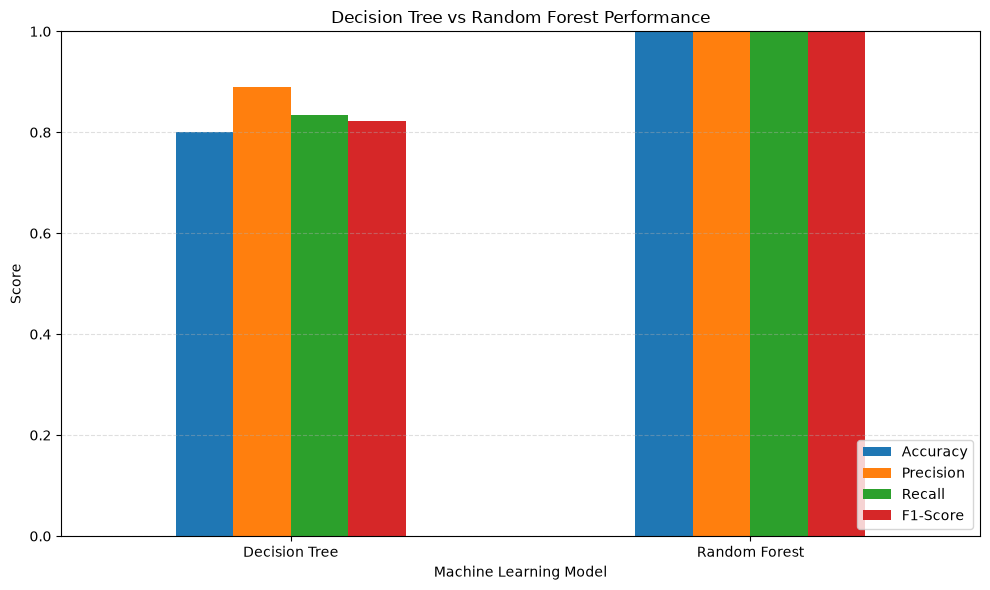

In [10]:
# Visual comparison of model performance

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Decision Tree vs Random Forest Performance")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [11]:
# Detailed classification reports

print("=" * 50)
print("DECISION TREE CLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_test,
    dt_predictions,
    zero_division=0
))

print("=" * 50)
print("RANDOM FOREST CLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       1.00      0.50      0.67         2
         Low       1.00      1.00      1.00         1
      Medium       0.67      1.00      0.80         2

    accuracy                           0.80         5
   macro avg       0.89      0.83      0.82         5
weighted avg       0.87      0.80      0.79         5

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       1.00      1.00      1.00         2
         Low       1.00      1.00      1.00         1
      Medium       1.00      1.00      1.00         2

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



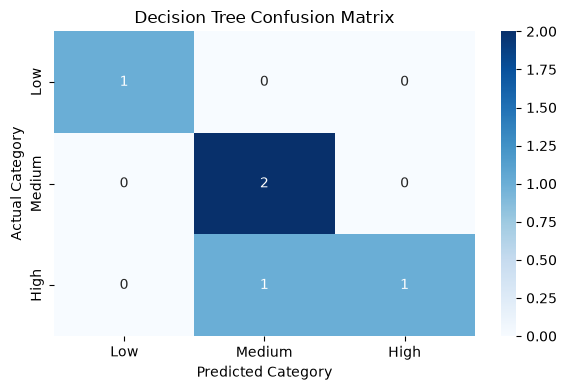

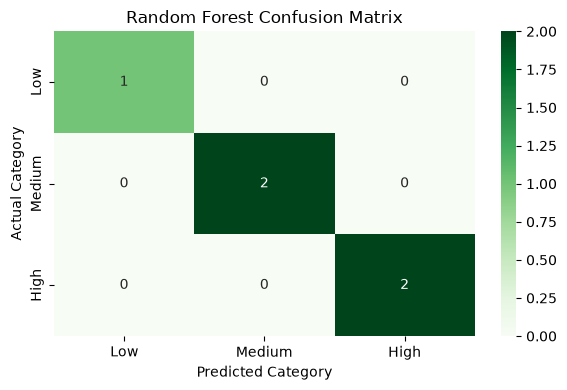

In [12]:
# Confusion matrix for Decision Tree

plt.figure(figsize=(6, 4))

cm_dt = confusion_matrix(
    y_test,
    dt_predictions,
    labels=["Low", "Medium", "High"]
)

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()


# Confusion matrix for Random Forest

plt.figure(figsize=(6, 4))

cm_rf = confusion_matrix(
    y_test,
    rf_predictions,
    labels=["Low", "Medium", "High"]
)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

Feature Importance:


,Feature,Decision Tree,Random Forest
0,Age,0.0,0.333
1,Annual_Income,1.0,0.389
2,Purchase_Frequency,0.0,0.278


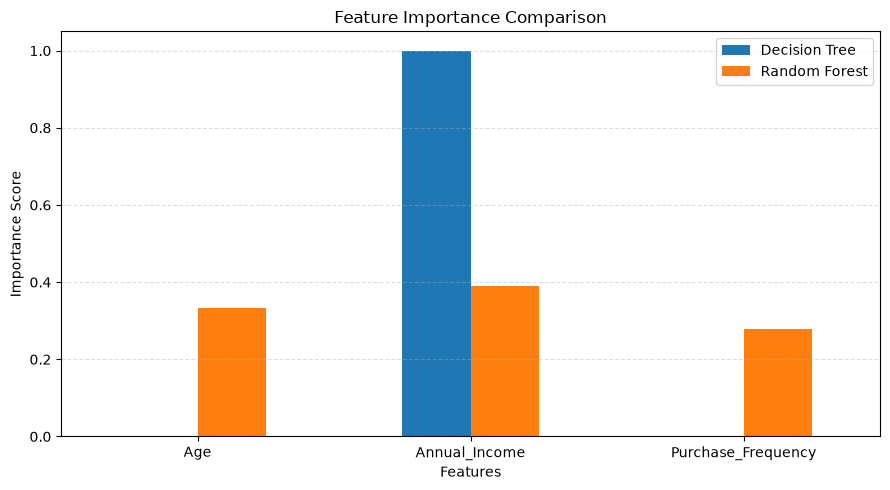

In [13]:
# Feature importance comparison

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Decision Tree": decision_tree.feature_importances_,
    "Random Forest": random_forest.feature_importances_
})

print("Feature Importance:")
display(feature_importance.round(3))

feature_importance.set_index("Feature").plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Feature Importance Comparison")
plt.ylabel("Importance Score")
plt.xlabel("Features")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [14]:
# Select the model with the highest F1-score

best_model_name = results_df.loc[
    results_df["F1-Score"].idxmax(), "Model"
]

if best_model_name == "Decision Tree":
    best_model = decision_tree
else:
    best_model = random_forest

print("Model Comparison Summary")
print("-" * 35)
print(results_df.round(3).to_string(index=False))

print("\nSelected Model:", best_model_name)
print("Selection criterion: Highest macro F1-score")

Model Comparison Summary
-----------------------------------
        Model  Accuracy  Precision  Recall  F1-Score
Decision Tree       0.8      0.889   0.833     0.822
Random Forest       1.0      1.000   1.000     1.000

Selected Model: Random Forest
Selection criterion: Highest macro F1-score


In [15]:
# Predict the spending category of a new customer

new_customer = pd.DataFrame({
    "Age": [29],
    "Annual_Income": [60000],
    "Purchase_Frequency": [7]
})

predicted_category = best_model.predict(new_customer)

print("New Customer Details:")
display(new_customer)

print("Selected Model:", best_model_name)
print("Predicted Spending Category:", predicted_category[0])

New Customer Details:


,Age,Annual_Income,Purchase_Frequency
0,29,60000,7


Selected Model: Random Forest
Predicted Spending Category: Medium


In [16]:
# Final project summary

print("=" * 55)
print("AI-BASED CUSTOMER SPENDING PREDICTION")
print("=" * 55)

print("Total Customers:", len(df))
print("Number of Features:", X.shape[1])
print("Spending Categories:", list(y.cat.categories))
print("Models Trained:", len(models))
print("Selected Model:", best_model_name)

print("\nDataset Category Distribution:")
print(df["Spending_Category"].value_counts())

print("\nModel Performance:")
display(results_df.round(3))

print("\nProject execution completed successfully!")

AI-BASED CUSTOMER SPENDING PREDICTION
Total Customers: 20
Number of Features: 3
Spending Categories: ['Low', 'Medium', 'High']
Models Trained: 2
Selected Model: Random Forest

Dataset Category Distribution:
Spending_Category
Medium    8
High      7
Low       5
Name: count, dtype: int64

Model Performance:


,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.8,0.889,0.833,0.822
1,Random Forest,1.0,1.000,1.000,1.000



Project execution completed successfully!


In [17]:
# Verify the required visualizations

print("Visualization checklist:")
print("1. Annual Income Distribution")
print("2. Annual Income vs Spending Score")
print("3. Purchase Frequency vs Spending Score")
print("4. Spending Category Distribution")
print("5. Feature Importance Comparison")

print("\nMake sure all five visualizations appear in your notebook.")

Visualization checklist:
1. Annual Income Distribution
2. Annual Income vs Spending Score
3. Purchase Frequency vs Spending Score
4. Spending Category Distribution
5. Feature Importance Comparison

Make sure all five visualizations appear in your notebook.
